<a href="https://colab.research.google.com/github/bsyeol/26AI_project/blob/main/final/FDS_Fast_Realtime_Benchmark.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 금융 이상거래 탐지 — LightGBM vs TabPFN 3.5-Fast
- 기존 `인공지능_시드.ipynb`의 `processed/full` 경로, 7개 입력 특징, seed 0~4, 1:20 저장 인덱스를 유지합니다. 기본 TabPFN 3.5는 실행하지 않습니다.
- 모든 비율에서 문맥 9,996건, 같은 시드에서는 두 모델에 동일 거래를 사용합니다. Validation 전체를 예측하며, 앞 50,000건(시간순)은 LightGBM 트리 수 선정용으로 따로 구분합니다. 주 성능 지표는 나머지 Validation에서 계산합니다. 전체 Validation 지표는 참고용(튜닝 구간 포함)입니다. Test는 사용하지 않습니다.
- LightGBM: learning_rate=0.05, num_leaves=31, 최대 2,000회, AP 기준 patience=50. 비율별 seed 0에서 선정한 트리 수를 5개 시드에 고정합니다. 이는 실무 표준값이 아니라 제한된 검증 기반 튜닝입니다. 튜닝 시간은 별도 기록합니다.
- TabPFN: 공식 3.5-Fast 기본 앙상블 설정, fit_with_cache, CUDA. LightGBM은 CPU. 실제 배포 구성의 비교이지 동일 장치에서의 연산량 비교가 아닙니다.
- 전체 Validation 추론 시간은 `perf_counter` 및 CUDA 동기화로 측정합니다. 첫 다운로드/워밍업은 제외하고, 매 실행 결과와 예측 확률을 Drive에 저장합니다. 모델 초기화는 별도로 기록합니다. GPU 런타임을 사용하세요.
- 출처: [LightGBM tuning](https://lightgbm.readthedocs.io/en/stable/Parameters-Tuning.html), [TabPFN 공식 저장소](https://github.com/PriorLabs/TabPFN).
## 실시간성 추가 실험
- 배치 크기 1, 100, 500, 1,000, 10,000건을 모두 측정합니다. 각 모델/비율/시드별 이미 적합된 모델에서 배치별 2회 warm-up, 20회 측정(총 4,000개 측정값)으로 재학습을 방지합니다.
- 가설적 모델 추론 예산: 1건 50ms, 100건 200ms, 500건 500ms, 1,000건 1,000ms. 금융권 공통 SLA가 아니며 10,000건은 제한을 설정하지 않습니다.
- 추론 예산을 P95가 충족하는지 평가합니다. 모델 API의 실제 경과 시간이며 배치 대기·네트워크·특징 추출 등은 미포함입니다. 실서비스 SLA 충족을 단정할 수 없습니다.
- 첫 실행 시 모델 라이선스 동의 또는 인증이 필요할 수 있습니다. Colab에서 GPU를 선택하고 위에서부터 모두 실행하세요.


In [14]:
# 1. 설치 (이미 호환 버전이 설치되어 있다면 생략 가능)
import subprocess, sys
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', '-U', 'tabpfn', 'lightgbm', 'pyarrow'])
# import 충돌이 발생하면 런타임을 재시작한 뒤 셀 2부터 실행합니다.

0

In [15]:
# 2. 환경, 경로, 실험 설정
from google.colab import drive
drive.mount('/content/drive')
import os, json, gc, time, hashlib, platform, uuid
from pathlib import Path
from importlib.metadata import version
import numpy as np
import pandas as pd
import torch
import lightgbm as lgb
from tabpfn import TabPFNClassifier
from tabpfn.constants import ModelVersion
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_curve, auc
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

ROOT = Path('/content/drive/MyDrive/26-2_AI_project/processed/full')
OUT = ROOT / 'lgbm_vs_tabpfn35_fast_realtime_v2'
OUT.mkdir(parents=True, exist_ok=True)
assert torch.cuda.is_available(), 'Colab GPU 런타임을 선택하세요.'
assert hasattr(ModelVersion, 'V3_5_FAST'), 'TabPFN 최신 버전 설치 후 런타임을 재시작하세요.'
assert (ROOT / 'settings.json').exists(), f'Drive 경로 또는 settings.json 확인: {ROOT}'
SETTINGS = json.loads((ROOT / 'settings.json').read_text(encoding='utf-8'))
BASE_FEATURES = SETTINGS['BASE_FEATURES']
CAT_FEATURES = SETTINGS['CATEGORICAL_FEATURES']
CAT_INDICES = [BASE_FEATURES.index(c) for c in CAT_FEATURES]
LABEL = SETTINGS['LABEL']
SEEDS = SETTINGS['SEEDS']
assert SEEDS == [0, 1, 2, 3, 4]
RATIOS = ['Original', '1:50', '1:20', '1:10']
FRAUD_COUNTS = {'Original':38, '1:50':196, '1:20':476, '1:10':909}
CONTEXT_SIZE = 9996
PRED_BATCH = 20000  # GPU 메모리가 부족하면 10000 또는 5000으로 변경하고 새 OUT 사용
TUNE_N = 50000
TARGET_FPR = 0.001
LATENCY_BATCHES = [1, 100, 500, 1000, 10000]
LATENCY_REPEATS = 20
LATENCY_WARMUPS = 2
SLA_MS = {1:50, 100:200, 500:500, 1000:1000}  # 연구용 추론 예산, 산업 공통 표준 아님
MAX_TREES = 2000
PATIENCE = 50
THREADS = min(8, len(os.sched_getaffinity(0)))
SESSION = uuid.uuid4().hex[:12]
CPU = next((s.split(':',1)[1].strip() for s in Path('/proc/cpuinfo').read_text().splitlines() if s.startswith('model name')), platform.processor())
ENV = dict(cpu=CPU, cpu_threads=THREADS, gpu=torch.cuda.get_device_name(0),
           gpu_memory=int(torch.cuda.get_device_properties(0).total_memory),
           python=platform.python_version(), cuda=torch.version.cuda,
           versions={p:version(p) for p in ['torch','tabpfn','lightgbm','scikit-learn','pandas','numpy','pyarrow']})

def write_json(path, obj):
    tmp = path.with_suffix(path.suffix + '.tmp')
    tmp.write_text(json.dumps(obj, ensure_ascii=False, indent=2), encoding='utf-8')
    os.replace(tmp, path)

def write_csv(path, data):
    tmp = path.with_suffix(path.suffix + '.tmp')
    data.to_csv(tmp, index=False)
    os.replace(tmp, path)

def file_hash(path):
    h = hashlib.md5()
    with open(path,'rb') as f:
        for chunk in iter(lambda:f.read(2**20), b''): h.update(chunk)
    return h.hexdigest()

DATA = ROOT / 'full_v1.parquet'
CONFIG = dict(data_md5=file_hash(DATA), seeds=SEEDS, ratios=RATIOS, fraud_counts=FRAUD_COUNTS,
              features=BASE_FEATURES, categorical=CAT_FEATURES, context_size=CONTEXT_SIZE,
              batch=PRED_BATCH, tune_n=TUNE_N, target_fpr=TARGET_FPR, max_trees=MAX_TREES,
              patience=PATIENCE, learning_rate=0.05, num_leaves=31,
              fast_fit_mode='fit_with_cache', latency_batches=LATENCY_BATCHES, latency_repeats=LATENCY_REPEATS,
              latency_warmups=LATENCY_WARMUPS, sla_ms={str(k):v for k,v in SLA_MS.items()}, environment=ENV)
config_path = OUT / 'config.json'
if config_path.exists():
    assert json.loads(config_path.read_text()) == CONFIG, '실험 설정/환경 변경: OUT을 새 경로로 지정하세요.'
else:
    write_json(config_path, CONFIG)
print(json.dumps(ENV, indent=2, ensure_ascii=False))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
{
  "cpu": "Intel(R) Xeon(R) CPU @ 2.20GHz",
  "cpu_threads": 8,
  "gpu": "NVIDIA L4",
  "gpu_memory": 23659151360,
  "python": "3.13.16",
  "cuda": "13.0",
  "versions": {
    "torch": "2.14.1+cu130",
    "tabpfn": "10.2.0",
    "lightgbm": "4.7.0",
    "scikit-learn": "1.6.1",
    "pandas": "2.2.3",
    "numpy": "2.4.6",
    "pyarrow": "26.0.1"
  }
}


In [16]:
# 3. 데이터와 고정 표본 준비 (Test는 평가하지 않음)
df = pd.read_parquet(DATA, columns=BASE_FEATURES+[LABEL,'split','date'])
assert df.index.equals(pd.RangeIndex(len(df)))
train = df[df['split'].eq('train')]
val = df[df['split'].eq('val')].sort_values('date', kind='stable')
assert len(val) > TUNE_N + max(LATENCY_BATCHES)
X_val = val[BASE_FEATURES].copy()
y_val = val[LABEL].to_numpy(dtype=np.int8)
X_tune = X_val.iloc[:TUNE_N]
y_tune = y_val[:TUNE_N]
assert set(np.unique(y_val)) == {0,1} and set(np.unique(y_tune)) == {0,1}
assert set(np.unique(y_val[TUNE_N:])) == {0,1}
fraud_rows = train.index[train[LABEL].eq(1)].to_numpy()
normal_rows = train.index[train[LABEL].eq(0)].to_numpy()
CONTEXT = {}
for ratio in RATIOS:
    for seed in SEEDS:
        n = FRAUD_COUNTS[ratio]
        rng = np.random.default_rng(seed)
        rows = np.sort(np.concatenate([rng.choice(fraud_rows,n,replace=False),
                     rng.choice(normal_rows,CONTEXT_SIZE-n,replace=False)]))
        if ratio == '1:20':
            saved = np.load(ROOT / f'context_seed{seed}.npy')
            assert np.array_equal(rows,saved), f'기존 seed {seed} 행 불일치'
        assert len(np.unique(rows)) == CONTEXT_SIZE
        assert df.loc[rows,'split'].eq('train').all()
        assert int(df.loc[rows,LABEL].sum()) == n
        CONTEXT[ratio,seed] = rows
np.savez_compressed(OUT/'contexts.npz', **{f'{r.replace(":","-")}_seed{s}':a for (r,s),a in CONTEXT.items()})
np.savez_compressed(OUT/'validation_index_labels.npz', rows=val.index.to_numpy(), y=y_val, tune_n=TUNE_N)
print('Train:',len(train),'Validation 전체:',len(val),'튜닝:',TUNE_N,'독립 Validation:',len(val)-TUNE_N)
print('튜닝 이상거래:',int(y_tune.sum()),'독립 Validation 이상거래:',int(y_val[TUNE_N:].sum()))
print('튜닝 마지막 날짜:',val['date'].iloc[TUNE_N-1], '평가 첫 날짜:',val['date'].iloc[TUNE_N])

def get_context(ratio,seed):
    rows = CONTEXT[ratio,seed]
    return df.loc[rows,BASE_FEATURES], df.loc[rows,LABEL].to_numpy()

Train: 2998429 Validation 전체: 356291 튜닝: 50000 독립 Validation: 306291
튜닝 이상거래: 276 독립 Validation 이상거래: 1427
튜닝 마지막 날짜: 2024-04-13 00:00:00 평가 첫 날짜: 2024-04-13 00:00:00


In [17]:
# 4. LightGBM 트리 수 선정 — ratio별 seed 0에서만 실행, 이후 고정
# AP 조기 종료. 튜닝 데이터는 최종 주요 지표에서 제외합니다.
def make_lgb(seed, n_trees):
    return lgb.LGBMClassifier(n_estimators=int(n_trees), learning_rate=0.05,
        num_leaves=31, objective='binary', metric='average_precision',
        random_state=seed, n_jobs=THREADS, verbosity=-1, deterministic=True,
        force_col_wise=True, device_type='cpu')

tune_path = OUT/'tree_selection.csv'
tuning = pd.read_csv(tune_path) if tune_path.exists() else pd.DataFrame()
for ratio in RATIOS:
    if not tuning.empty and ratio in tuning['ratio'].values: continue
    X,y = get_context(ratio,0)
    model = make_lgb(0,MAX_TREES)
    t = time.perf_counter()
    model.fit(X,y,categorical_feature=CAT_FEATURES,eval_set=[(X_tune,y_tune)],
              callbacks=[lgb.early_stopping(PATIENCE,first_metric_only=True,verbose=False)])
    elapsed = time.perf_counter()-t
    n_trees = int(model.best_iteration_ or model.n_estimators_)
    row = dict(ratio=ratio,selected_trees=n_trees,trained_trees=int(model.n_estimators_),
               tune_AP=float(model.best_score_['valid_0']['average_precision']),
               tuning_seconds=elapsed,session=SESSION)
    tuning = pd.concat([tuning,pd.DataFrame([row])],ignore_index=True)
    write_csv(tune_path,tuning)
    print(row)
    del model
TREES = tuning.set_index('ratio')['selected_trees'].astype(int).to_dict()
display(tuning)

,ratio,selected_trees,trained_trees,tune_AP,tuning_seconds,session
0,Original,53,53,0.503640,0.278042,2d5d37bbef90
1,1:50,38,38,0.585946,0.115754,2d5d37bbef90
2,1:20,67,67,0.512464,0.166167,2d5d37bbef90
3,1:10,1,1,0.513539,0.076923,2d5d37bbef90


In [20]:
import os
from google.colab import userdata

os.environ["TABPFN_TOKEN"] = userdata.get("TABPFN_TOKEN")

print("TabPFN 인증 키 로드 완료")

TabPFN 인증 키 로드 완료


In [21]:
# 5. 모델 생성 및 측정 함수
MODELS = ['LightGBM','TabPFN 3.5-Fast']
def make_model(name,ratio,seed):
    if name == 'LightGBM': return make_lgb(seed,TREES[ratio])
    return TabPFNClassifier.create_default_for_version(ModelVersion.V3_5_FAST,
        device='cuda', random_state=seed, categorical_features_indices=CAT_INDICES,
        fit_mode='fit_with_cache')

def sync(name):
    if name != 'LightGBM': torch.cuda.synchronize()

def fit_model(model,name,X,y):
    if name == 'LightGBM': model.fit(X,y,categorical_feature=CAT_FEATURES)
    else: model.fit(X,y)

def timed(name,fn):
    sync(name); start = time.perf_counter(); result = fn(); sync(name)
    return result,time.perf_counter()-start

def predict_all(model):
    p = np.empty(len(X_val),dtype=np.float64)
    positive = list(model.classes_).index(1)
    for i in range(0,len(X_val),PRED_BATCH):
        p[i:i+PRED_BATCH] = model.predict_proba(X_val.iloc[i:i+PRED_BATCH])[:,positive]
    return p

def scores(y,p):
    precision,recall,_ = precision_recall_curve(y,p)
    fpr,tpr,thresholds = roc_curve(y,p,drop_intermediate=False)
    ok = np.flatnonzero(fpr <= TARGET_FPR)
    j = ok[np.argmax(tpr[ok])]
    return dict(AP=float(average_precision_score(y,p)), PR_AUC=float(auc(recall,precision)),
                Recall_at_FPR=float(tpr[j]), achieved_FPR=float(fpr[j]))

def measure_latency(model,name,ratio,seed):
    # 같은 seed와 배치 크기에서는 모든 모델/비율이 같은 거래 구간을 조회
    # 적합된 모델에서 직접 predict_proba 호출. 데이터 슬라이스/저장/지표 계산 제외.
    records = []
    X_eval = X_val.iloc[TUNE_N:]
    for b in LATENCY_BATCHES:
        rng = np.random.default_rng(np.random.SeedSequence([seed,b,2026]))
        starts = rng.integers(0,len(X_eval)-b+1,size=LATENCY_WARMUPS+LATENCY_REPEATS)
        for j,start in enumerate(starts):
            batch = X_eval.iloc[int(start):int(start)+b]
            if j < LATENCY_WARMUPS:
                model.predict_proba(batch)
                sync(name)
            else:
                pred,seconds = timed(name,lambda:model.predict_proba(batch))
                assert pred.shape[0] == b
                records.append(dict(model=name,ratio=ratio,seed=seed,session=SESSION,
                                    batch_size=b,repeat=j-LATENCY_WARMUPS,
                                    latency_ms=seconds*1000))
                del pred
    return pd.DataFrame(records)

def cleanup():
    gc.collect(); torch.cuda.empty_cache()

# 예측 횟수가 많으므로 전체 표본으로 1회 warm-up, 다운로드/초기 CUDA 비용 제외
# 인증이 필요하면 공식 Prior Labs 안내에 따라 로그인합니다.
# https://github.com/PriorLabs/TabPFN
for name in MODELS:
    X,y = get_context('1:10',0)
    warm = make_model(name,'1:10',0)
    fit_model(warm,name,X,y)
    warm.predict_proba(X_val.iloc[:PRED_BATCH])
    sync(name)
    print('Warm-up 완료:',name)
    del warm
    cleanup()

Warm-up 완료: LightGBM


tabpfn-v3.5-fast-20260909.safetensors: reconstructing file:   0%|          |  0.00B /  334MB            

tabpfn-v3.5-fast-20260909.safetensors: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/36.0 [00:00<?, ?B/s]

Warm-up 완료: TabPFN 3.5-Fast


In [22]:
# 6. 전체 실험 (40회) — 완료한 run은 재개 시 자동 건너뜀
# 성능 계산/Drive 저장/진행 표시 시간은 측정에서 제외.
# 모델 실행 순서는 seed와 ratio에 따라 교대합니다.
RESULT = OUT/'results.csv'
results = pd.read_csv(RESULT) if RESULT.exists() else pd.DataFrame()
LAT_DIR = OUT/'latency_runs'
LAT_DIR.mkdir(exist_ok=True)
def latency_path(name,ratio,seed):
    return LAT_DIR/f'{name.replace(" ","_")}_{ratio.replace(":","-")}_seed{seed}.csv'
completed = set(zip(results.model,results.ratio,results.seed)) if not results.empty else set()
for key in completed:
    assert latency_path(*key).exists(), f'완료 기록에 지연 시간 파일 누락: {key}'
plan = []
for ri,ratio in enumerate(RATIOS):
    for seed in SEEDS:
        order = MODELS if (ri+seed)%2 == 0 else MODELS[::-1]
        for name in order: plan.append((name,ratio,seed))
pending = [x for x in plan if x not in completed]
print(f'완료 {len(completed)}/{len(plan)}, 남은 실행 {len(pending)}')

for name,ratio,seed in tqdm(pending,desc='Benchmark'):
    X,y = get_context(ratio,seed)
    model,init_time = timed(name,lambda:make_model(name,ratio,seed))
    try:
        _,fit_time = timed(name,lambda:fit_model(model,name,X,y))
        p,inference_time = timed(name,lambda:predict_all(model))
        assert np.isfinite(p).all()
        latency = measure_latency(model,name,ratio,seed)
        assert len(latency) == len(LATENCY_BATCHES)*LATENCY_REPEATS
        write_csv(latency_path(name,ratio,seed),latency)
        primary = scores(y_val[TUNE_N:],p[TUNE_N:])
        full = {'full_'+k:v for k,v in scores(y_val,p).items()}
        row = dict(model=name,ratio=ratio,seed=seed,session=SESSION,
                   train_n=len(y),train_fraud=int(y.sum()),eval_n=len(y_val),
                   metric_n=len(y_val)-TUNE_N,batch=PRED_BATCH,
                   actual_trees=int(model.booster_.num_trees()) if name=='LightGBM' else None,
                   tabpfn_estimators=str(getattr(model,'n_estimators_',getattr(model,'n_estimators',''))) if name!='LightGBM' else None,
                   init_time=init_time,fit_time=fit_time,inference_time=inference_time,
                   total_time=fit_time+inference_time,**primary,**full)
        # 확률도 저장하므로 PR 곡선/ROC 및 지표 재계산 시 모델 재실행 불필요
        filename = f'{name.replace(" ","_")}_{ratio.replace(":","-")}_seed{seed}.npy'
        temp = OUT/(filename+'.tmp')
        with open(temp,'wb') as f: np.save(f,p)
        os.replace(temp,OUT/filename)
        results = pd.concat([results,pd.DataFrame([row])],ignore_index=True)
        write_csv(RESULT,results)
        tqdm.write(f'{name} {ratio} seed={seed} | AP={row["AP"]:.4f} PR-AUC={row["PR_AUC"]:.4f} Recall={row["Recall_at_FPR"]:.4f} | fit={fit_time:.3f}s infer={inference_time:.3f}s')
    finally:
        del model
        cleanup()

완료 0/40, 남은 실행 40


Benchmark:   0%|          | 0/40 [00:00<?, ?it/s]

LightGBM Original seed=0 | AP=0.5506 PR-AUC=0.5511 Recall=0.3097 | fit=0.026s infer=0.126s
TabPFN 3.5-Fast Original seed=0 | AP=0.5253 PR-AUC=0.5245 Recall=0.2670 | fit=1.360s infer=35.061s
TabPFN 3.5-Fast Original seed=1 | AP=0.4930 PR-AUC=0.4922 Recall=0.2488 | fit=1.382s infer=35.522s
LightGBM Original seed=1 | AP=0.4949 PR-AUC=0.5002 Recall=0.2446 | fit=0.024s infer=0.114s
LightGBM Original seed=2 | AP=0.5414 PR-AUC=0.5534 Recall=0.2586 | fit=0.029s infer=0.154s
TabPFN 3.5-Fast Original seed=2 | AP=0.5469 PR-AUC=0.5463 Recall=0.3329 | fit=1.385s infer=36.052s
TabPFN 3.5-Fast Original seed=3 | AP=0.5035 PR-AUC=0.5027 Recall=0.2551 | fit=1.399s infer=36.047s
LightGBM Original seed=3 | AP=0.4697 PR-AUC=0.4696 Recall=0.1710 | fit=0.026s infer=0.143s
LightGBM Original seed=4 | AP=0.5134 PR-AUC=0.5149 Recall=0.2922 | fit=0.028s infer=0.153s
TabPFN 3.5-Fast Original seed=4 | AP=0.5369 PR-AUC=0.5362 Recall=0.2894 | fit=1.417s infer=36.148s
TabPFN 3.5-Fast 1:50 seed=0 | AP=0.5543 PR-AUC=0.5

AP                  PR_AUC                 \
                             mean      std count     mean      std count   
ratio    model                                                             
Original LightGBM         0.51401  0.03323     5  0.51783  0.03543     5   
         TabPFN 3.5-Fast  0.52112  0.02257     5  0.52038  0.02259     5   
1:50     LightGBM         0.52069  0.02373     5  0.52625  0.02664     5   
         TabPFN 3.5-Fast  0.55343  0.01912     5  0.55302  0.01917     5   
1:20     LightGBM         0.52128  0.01595     5  0.52351  0.01627     5   
         TabPFN 3.5-Fast  0.54832  0.01909     5  0.54772  0.01918     5   
1:10     LightGBM         0.48675  0.00781     5  0.51586  0.02396     5   
         TabPFN 3.5-Fast  0.55899  0.02173     5  0.55842  0.02183     5   

                         Recall_at_FPR                fit_time                 \
                                  mean      std count     mean      std count   
ratio    model                                                                  
Original LightGBM              0.25522  0.05376     5  0.02624  0.00194     5   
         TabPFN 3.5-Fast       0.27863  0.03406     5  1.38871  0.02130     5   
1:50     LightGBM              0.27022  0.02882     5  0.01948  0.00167     5   
         TabPFN 3.5-Fast       0.29292  0.04165     5  1.40853  0.00736     5   
1:20     LightGBM              0.26601  0.01999     5  0.03582  0.00098     5   
         TabPFN 3.5-Fast       0.30638  0.03026     5  1.40473  0.01623     5   
1:10     LightGBM              0.11843  0.10078     5  0.00799  0.00039     5   
         TabPFN 3.5-Fast       0.31507  0.02484     5  1.40715  0.01474     5   

                         inference_time                total_time           \
                                   mean      std count       mean      std   
ratio    model                                                               
Original LightGBM               0.13817  0.01768     5    0.16440  0.01943   
         TabPFN 3.5-Fast       35.76606  0.46419     5   37.15477  0.48299   
1:50     LightGBM               0.08641  0.01375     5    0.10589  0.01385   
         TabPFN 3.5-Fast       36.10227  0.05548     5   37.51081  0.05503   
1:20     LightGBM               0.13081  0.01466     5    0.16663  0.01388   
         TabPFN 3.5-Fast       36.17113  0.04900     5   37.57586  0.05531   
1:10     LightGBM               0.03684  0.00262     5    0.04484  0.00292   
         TabPFN 3.5-Fast       36.15578  0.12195     5   37.56293  0.13468   

                                
                         count  
ratio    model                  
Original LightGBM            5  
         TabPFN 3.5-Fast     5  
1:50     LightGBM            5  
         TabPFN 3.5-Fast     5  
1:20     LightGBM            5  
         TabPFN 3.5-Fast     5  
1:10     LightGBM            5  
         TabPFN 3.5-Fast     5

모든 조합 5회 완료: True
트리 수 선정 결과:


,ratio,selected_trees,tuning_seconds
0,Original,53,0.278042
1,1:50,38,0.115754
2,1:20,67,0.166167
3,1:10,1,0.076923


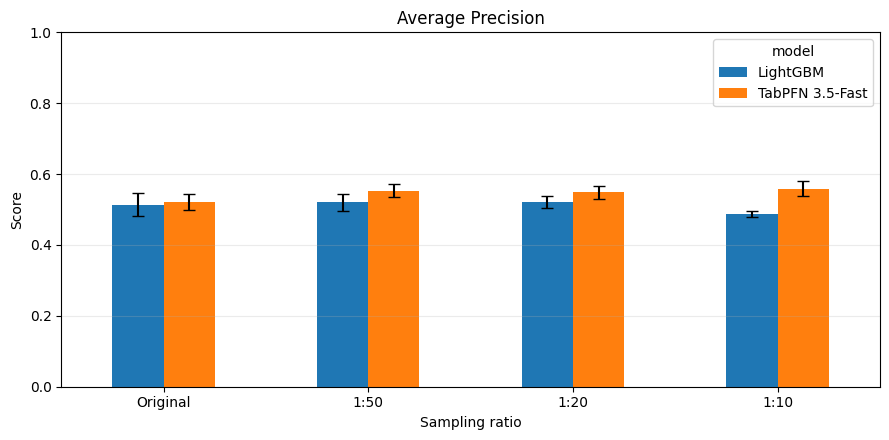

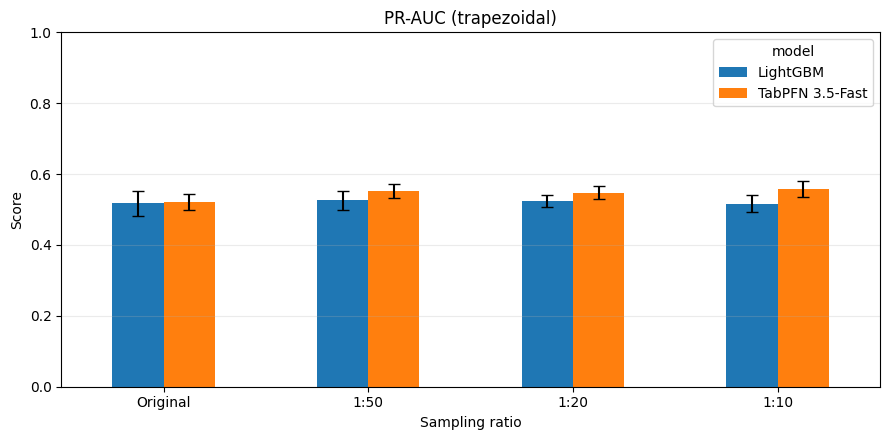

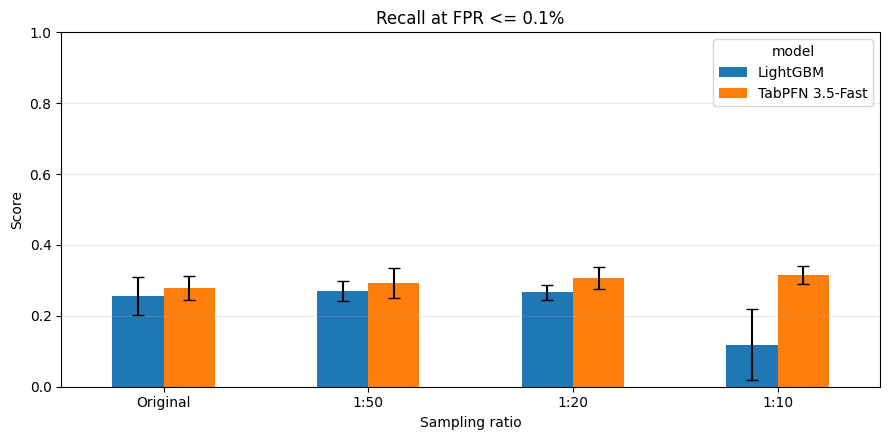

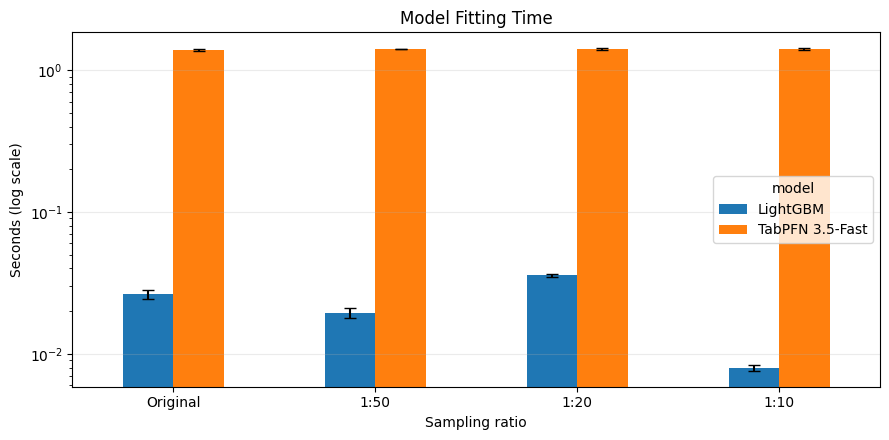

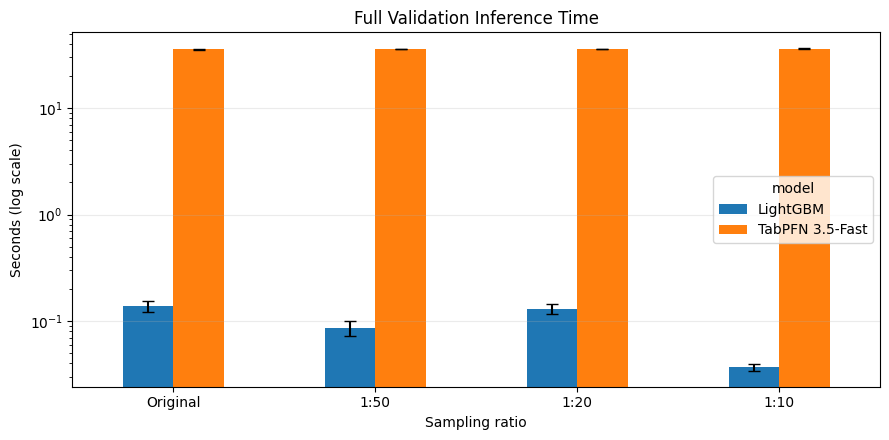

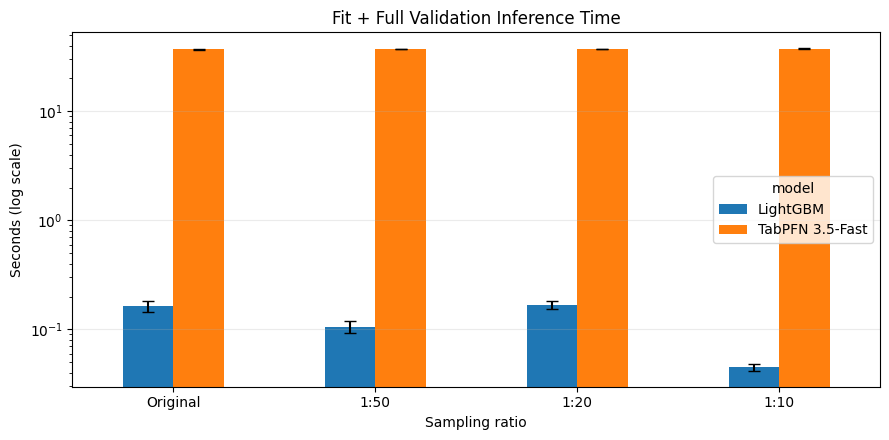

결과 경로: /content/drive/MyDrive/26-2_AI_project/processed/full/lgbm_vs_tabpfn35_fast_realtime_v2


In [23]:
# 7. 결과 표 및 그래프 — 완료된 결과만 표시, n=5 확인
results = pd.read_csv(RESULT)
assert not results.duplicated(['model','ratio','seed']).any()
metrics = ['AP','PR_AUC','Recall_at_FPR','fit_time','inference_time','total_time']
stats = results.groupby(['ratio','model'])[metrics].agg(['mean','std','count'])
summary = stats.reindex(pd.MultiIndex.from_product([RATIOS,MODELS],names=['ratio','model']))
summary.to_csv(OUT/'summary.csv')
display(summary.round(5))
counts = results.groupby(['ratio','model']).size().reindex(summary.index,fill_value=0)
print('모든 조합 5회 완료:',bool(counts.eq(len(SEEDS)).all()))
print('트리 수 선정 결과:')
display(tuning[['ratio','selected_trees','tuning_seconds']])
titles = {'AP':'Average Precision','PR_AUC':'PR-AUC (trapezoidal)',
          'Recall_at_FPR':'Recall at FPR <= 0.1%','fit_time':'Model Fitting Time',
          'inference_time':'Full Validation Inference Time','total_time':'Fit + Full Validation Inference Time'}
for m in metrics:
    means = stats[m]['mean'].unstack().reindex(index=RATIOS,columns=MODELS)
    stds = stats[m]['std'].unstack().reindex(index=RATIOS,columns=MODELS)
    ax = means.plot(kind='bar',yerr=stds.fillna(0),capsize=4,rot=0,figsize=(9,4.5),logy=m.endswith('_time'))
    ax.set_title(titles[m]); ax.set_xlabel('Sampling ratio')
    ax.set_ylabel('Seconds (log scale)' if m.endswith('_time') else 'Score')
    if not m.endswith('_time'): ax.set_ylim(0,1)
    ax.grid(axis='y',alpha=.25)
    plt.tight_layout(); plt.savefig(OUT/f'{m}.png',dpi=180); plt.show(); plt.close()
print('결과 경로:',OUT)

P95 / 지연 시간 단위: ms, throughput: 거래/초


,ratio,model,batch_size,mean_ms,std_ms,median_ms,p95_ms,count,throughput_tps,target_ms,p95_meets_target,within_target_fraction
0,1:10,LightGBM,1,0.978,0.067,0.946,1.112,100,1022.104,50.0,PASS,1.0
1,1:10,LightGBM,100,0.993,0.074,0.954,1.136,100,100714.018,200.0,PASS,1.0
2,1:10,LightGBM,500,1.030,0.071,0.988,1.153,100,485350.633,500.0,PASS,1.0
3,1:10,LightGBM,1000,1.050,0.079,1.015,1.215,100,952338.895,1000.0,PASS,1.0
4,1:10,LightGBM,10000,1.436,0.109,1.388,1.668,100,6963362.692,NaN,N/A,NaN
5,1:10,TabPFN 3.5-Fast,1,42.899,2.648,41.757,46.694,100,23.311,50.0,PASS,1.0
6,1:10,TabPFN 3.5-Fast,100,44.964,3.188,42.977,49.533,100,2224.014,200.0,PASS,1.0
7,1:10,TabPFN 3.5-Fast,500,62.212,2.535,60.722,66.043,100,8036.995,500.0,PASS,1.0
8,1:10,TabPFN 3.5-Fast,1000,104.177,1.978,104.026,107.444,100,9599.094,1000.0,PASS,1.0
9,1:10,TabPFN 3.5-Fast,10000,1012.481,5.144,1012.662,1019.965,100,9876.730,NaN,N/A,NaN


완료된 각 조합의 측정 횟수:


model                LightGBM  TabPFN 3.5-Fast
ratio    batch_size                           
1:10     1                100              100
         100              100              100
         500              100              100
         1000             100              100
         10000            100              100
1:20     1                100              100
         100              100              100
         500              100              100
         1000             100              100
         10000            100              100
1:50     1                100              100
         100              100              100
         500              100              100
         1000             100              100
         10000            100              100
Original 1                100              100
         100              100              100
         500              100              100
         1000             100              100
         10000            100              100

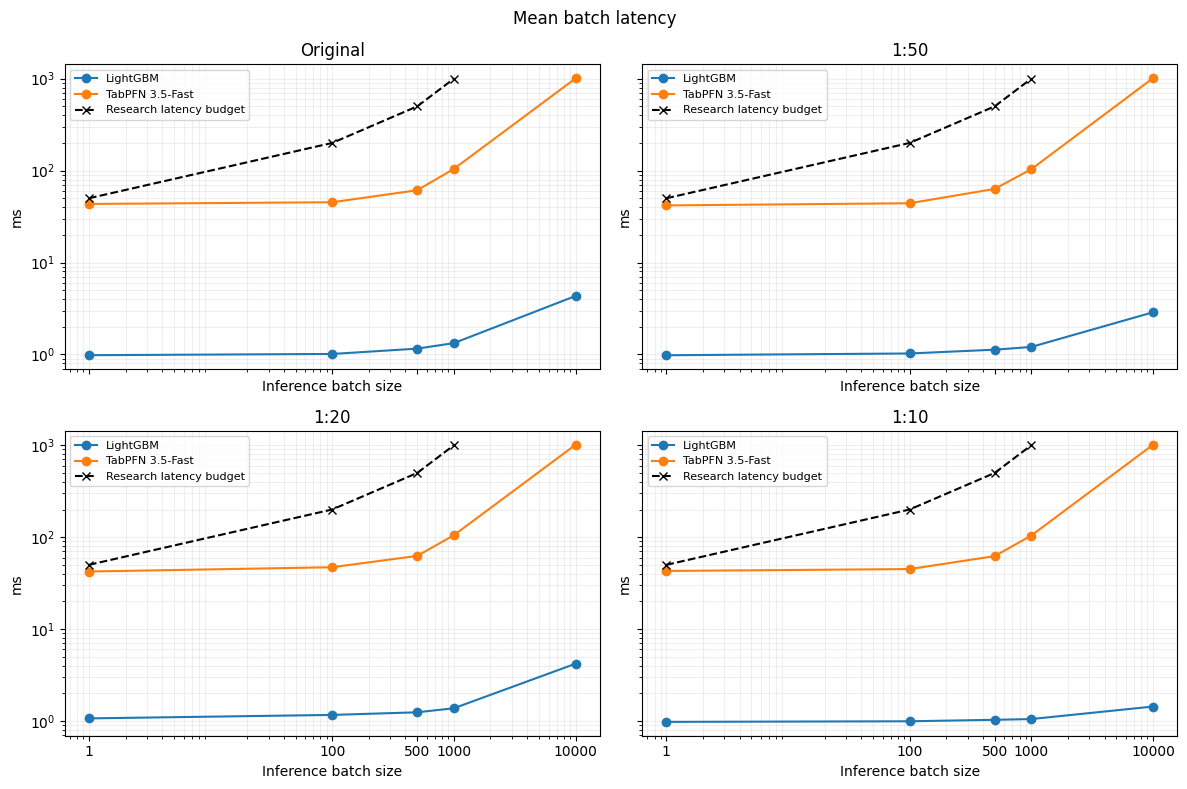

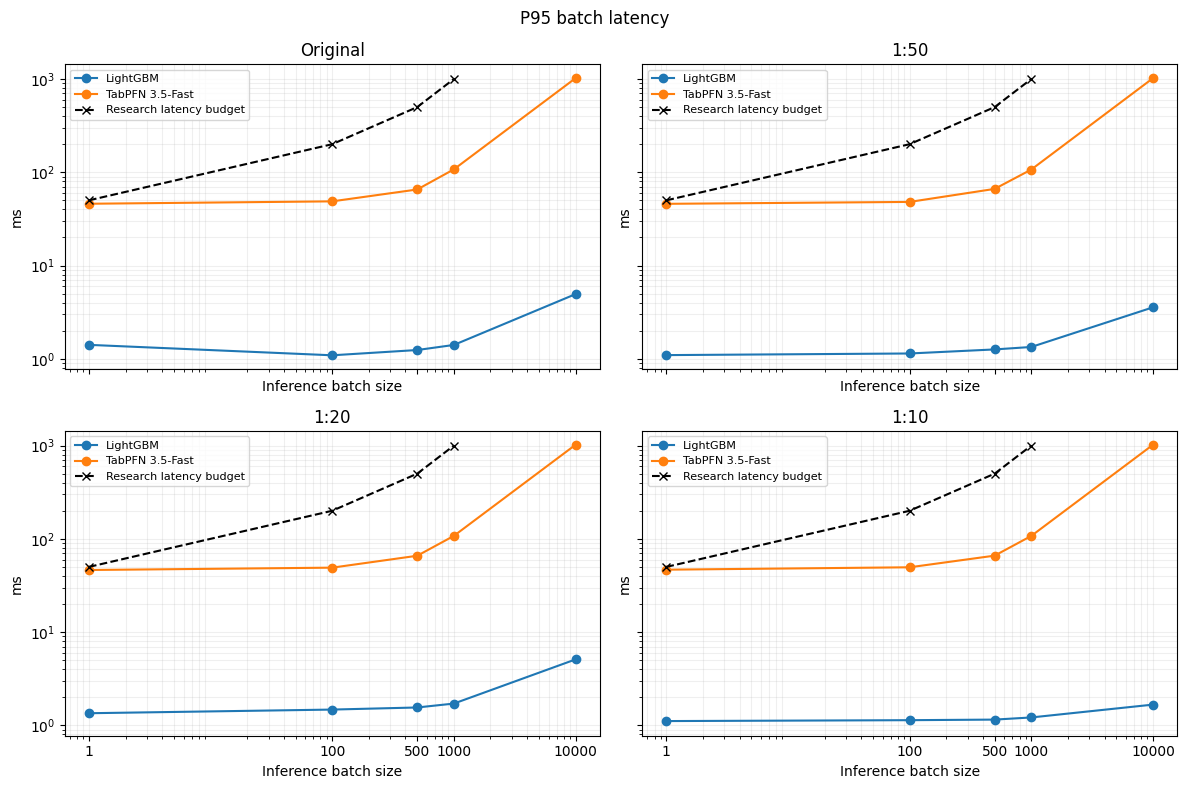

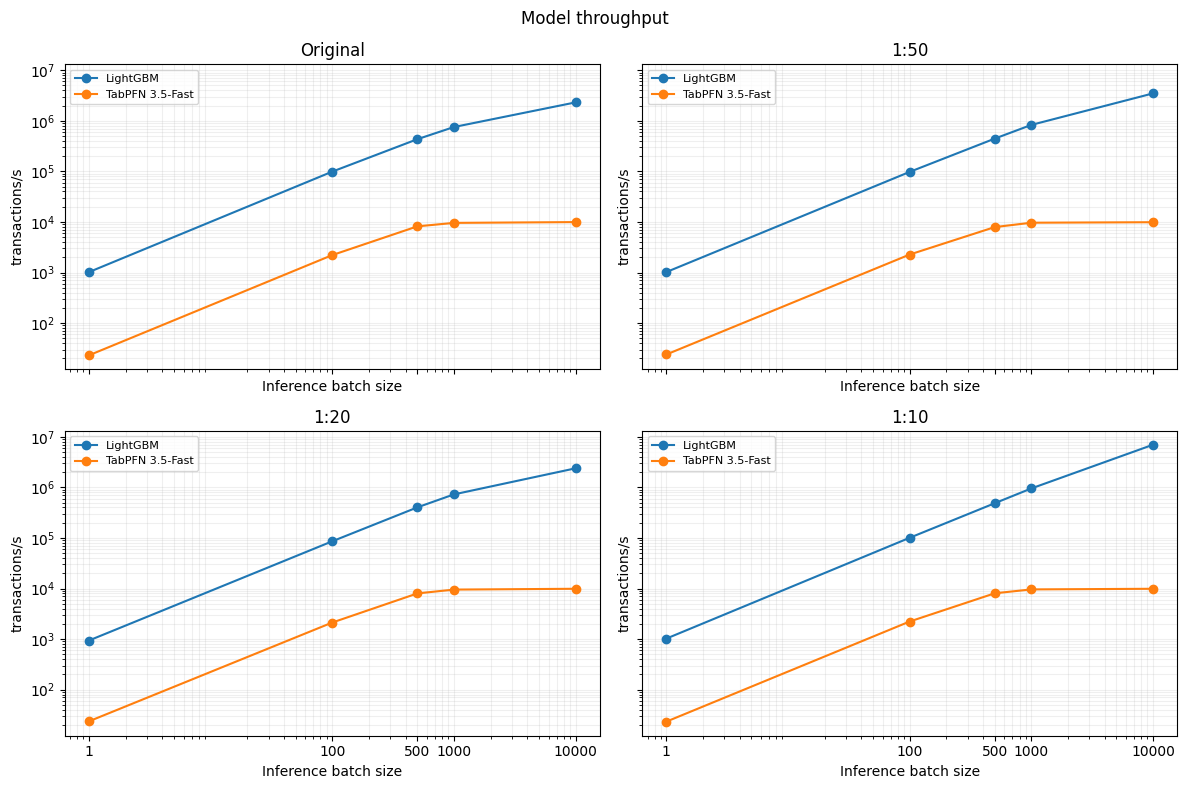

,ratio,model,batch_size,p95_ms,target_ms,p95_meets_target,within_target_fraction,PR_AUC,Recall_at_FPR
0,1:10,LightGBM,1,1.1115,50.0,PASS,1.0,0.5159,0.1184
1,1:10,LightGBM,100,1.1363,200.0,PASS,1.0,0.5159,0.1184
2,1:10,LightGBM,500,1.1526,500.0,PASS,1.0,0.5159,0.1184
3,1:10,LightGBM,1000,1.2155,1000.0,PASS,1.0,0.5159,0.1184
4,1:10,LightGBM,10000,1.6685,NaN,N/A,NaN,0.5159,0.1184
5,1:10,TabPFN 3.5-Fast,1,46.6941,50.0,PASS,1.0,0.5584,0.3151
6,1:10,TabPFN 3.5-Fast,100,49.5327,200.0,PASS,1.0,0.5584,0.3151
7,1:10,TabPFN 3.5-Fast,500,66.0432,500.0,PASS,1.0,0.5584,0.3151
8,1:10,TabPFN 3.5-Fast,1000,107.4442,1000.0,PASS,1.0,0.5584,0.3151
9,1:10,TabPFN 3.5-Fast,10000,1019.9647,NaN,N/A,NaN,0.5584,0.3151


저장 완료: /content/drive/MyDrive/26-2_AI_project/processed/full/lgbm_vs_tabpfn35_fast_realtime_v2


In [24]:
# 8. 배치 크기별 지연 시간 / P95 / 처리량 / 추론 예산 충족 여부
# 각 seed의 20회 측정값을 보존하고, 모든 seed의 측정값을 합쳐 경험적 P95 산출.
results = pd.read_csv(RESULT)
keys = list(zip(results.model,results.ratio,results.seed))
assert keys, '먼저 전체 실험 셀을 실행하세요.'
latency = pd.concat([pd.read_csv(latency_path(*k)) for k in keys],ignore_index=True)
assert not latency.duplicated(['model','ratio','seed','batch_size','repeat']).any()
assert latency.groupby(['model','ratio','seed','batch_size']).size().eq(LATENCY_REPEATS).all()
write_csv(OUT/'latency_raw.csv',latency)

def p95(x):
    # 보수적 경험적 95백분위수 (nearest rank)
    a = np.sort(np.asarray(x))
    return float(a[max(0,int(np.ceil(.95*len(a)))-1)])

per_seed = latency.groupby(['ratio','model','seed','batch_size']).latency_ms.agg(
    mean_ms='mean',median_ms='median',p95_ms=p95,count='count').reset_index()
per_seed['throughput_tps'] = per_seed.batch_size*1000/per_seed.mean_ms
write_csv(OUT/'latency_per_seed.csv',per_seed)
summary_latency = latency.groupby(['ratio','model','batch_size']).latency_ms.agg(
    mean_ms='mean',std_ms='std',median_ms='median',p95_ms=p95,count='count').reset_index()
summary_latency['throughput_tps'] = summary_latency.batch_size*1000/summary_latency.mean_ms
summary_latency['target_ms'] = summary_latency.batch_size.map(SLA_MS)
summary_latency['p95_meets_target'] = [
    'N/A' if pd.isna(t) else ('PASS' if p<=t else 'FAIL')
    for p,t in zip(summary_latency.p95_ms,summary_latency.target_ms)]
latency['target_ms'] = latency.batch_size.map(SLA_MS)
latency['within_target'] = np.where(latency.target_ms.notna(),latency.latency_ms<=latency.target_ms,np.nan)
shares = latency.groupby(['ratio','model','batch_size']).within_target.mean().rename('within_target_fraction').reset_index()
summary_latency = summary_latency.merge(shares,on=['ratio','model','batch_size'])
write_csv(OUT/'latency_summary.csv',summary_latency)
print('P95 / 지연 시간 단위: ms, throughput: 거래/초')
display(summary_latency.round(3))
print('완료된 각 조합의 측정 횟수:')
display(summary_latency.pivot(index=['ratio','batch_size'],columns='model',values='count'))
# 두 모델의 결과와 연구용 지연 시간 기준을 같은 그래프에 표시 (비율별 subplot)
for metric,title,unit in [('mean_ms','Mean batch latency','ms'),('p95_ms','P95 batch latency','ms'),('throughput_tps','Model throughput','transactions/s')]:
    fig,axes = plt.subplots(2,2,figsize=(12,8),sharex=True,sharey=True)
    for ratio,ax in zip(RATIOS,axes.ravel()):
        for name in MODELS:
            a = summary_latency[(summary_latency.ratio==ratio)&(summary_latency.model==name)].sort_values('batch_size')
            ax.plot(a.batch_size,a[metric],marker='o',label=name)
        if metric in ['mean_ms','p95_ms']:
            ax.plot(list(SLA_MS),list(SLA_MS.values()),'k--',marker='x',label='Research latency budget')
        ax.set_xscale('log'); ax.set_yscale('log')
        ax.set_xticks(LATENCY_BATCHES,labels=[str(b) for b in LATENCY_BATCHES])
        ax.set_title(ratio); ax.set_xlabel('Inference batch size'); ax.set_ylabel(unit)
        ax.grid(True,which='both',alpha=.2); ax.legend(fontsize=8)
    fig.suptitle(title); fig.tight_layout()
    fig.savefig(OUT/f'latency_{metric}.png',dpi=180); plt.show(); plt.close(fig)
# 실시간성 + 탐지 성능을 한 표에서 비교 (Validation, seed 평균)
performance = results.groupby(['ratio','model'])[['AP','PR_AUC','Recall_at_FPR','fit_time','inference_time']].mean().reset_index()
tradeoff = summary_latency.merge(performance,on=['ratio','model'])
write_csv(OUT/'realtime_tradeoff.csv',tradeoff)
display(tradeoff[['ratio','model','batch_size','p95_ms','target_ms','p95_meets_target','within_target_fraction','PR_AUC','Recall_at_FPR']].round(4))
print('저장 완료:',OUT)


## 해석 및 주의사항
- 주요 성능 지표는 트리 수 선정에 사용하지 않은 Validation 나머지 구간에서 계산합니다. `full_*`은 전체 Validation의 참고값입니다. Recall은 해당 평가 데이터의 ROC에서 FPR ≤ 0.001인 점 중 최대 TPR이며, 실제 운영 임계값 성능과 동일하지 않습니다. 최종 운영 임계값은 별도 검증 구간에서 고정하고 Test에서 확인해야 합니다.
- `fit_time`은 준비/적합 시간이며 TabPFN 사전학습을 포함하지 않습니다. `total_time`은 적합+전체 추론이며 모델 객체 생성(`init_time`) 및 튜닝 비용(`tree_selection.csv`)은 별도입니다. 최초 다운로드 및 워밍업 제외. 모델 내부의 로컬 체크포인트 로딩이 fit에 포함될 수 있습니다.
- 5개 seed는 표본 변화에 대한 반복이며 독립적인 5-fold가 아닙니다. 표준편차는 seed 및 실행 환경의 변동을 포함합니다. 여러 Colab 세션을 합치면 동일 사양이어도 부하 차이가 있을 수 있으므로 `session`별 시간 차이를 확인하세요.
- Original은 원래 비율에 가까운 고정 38개 양성 표본입니다. 모든 조건의 총 학습 건수는 동일합니다. 클래스 가중치/추가 샘플링은 하지 않습니다.
- 실행 속도가 너무 느리거나 OOM이면 PRED_BATCH를 줄이고 새로운 OUT 폴더로 실험을 시작하세요. 기존 결과와 섞지 않습니다. 두 모델 모두 전체 Validation을 예측합니다. Fast의 앙상블 수는 공식 기본값을 사용합니다.
- 최종 Test는 GRU/Transformer 결합 등 모델 선정이 끝난 뒤 평가합니다. 이 노트북은 기존 원본 파일을 수정하지 않습니다.
- 실시간성 실험은 이미 적합된 모델의 `predict_proba()` 호출 전체를 측정합니다. 배치별 2회 준비 후 20회, 각 비율/모델 5개 seed 합계 100회 표본에서 P95를 계산합니다. 개별 seed P95도 별도 저장합니다. 배치 크기별 평균 처리량은 batch_size / 평균 추론 초이며 동시 요청 또는 서비스 TPS가 아닙니다.
- 1건 50ms, 100건 200ms, 500건 500ms, 1,000건 1,000ms는 연구에서 정한 모델 추론 예산이며 금융권 표준이 아닙니다. 10,000건에는 기준을 두지 않았습니다. PASS는 모델 P95만 기준 이하라는 의미입니다. 배치 형성 대기 시간과 특징 생성 등은 측정하지 않습니다.
- 시간 절약을 위해 각 모델을 한 번 적합한 후 전체 평가 및 모든 배치 지연 시간 실험을 수행합니다. 원본 데이터 및 기존 실험 결과는 변경하지 않습니다.
